In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.style.use("seaborn-v0_8")

df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

df.shape

(6267, 44)

In [2]:
variables_descriptivas = [
    "pl_rade",
    "pl_bmasse",
    "densidad_calculada",
    "pl_orbper",
    "pl_orbsmax",
    "st_teff",
    "st_mass",
    "st_rad",
    "st_met",
    "st_age",
    "sy_dist"
]

tabla_descriptiva = df[variables_descriptivas].describe().T

tabla_descriptiva["IQR"] = tabla_descriptiva["75%"] - tabla_descriptiva["25%"]

tabla_descriptiva = tabla_descriptiva[
    ["count", "50%", "25%", "75%", "IQR", "min", "max"]
]

tabla_descriptiva = tabla_descriptiva.rename(columns={
    "count": "N",
    "50%": "mediana",
    "25%": "Q1",
    "75%": "Q3",
    "min": "minimo",
    "max": "maximo"
})

tabla_descriptiva

,N,mediana,Q1,Q3,IQR,minimo,maximo
pl_rade,6223.0,2.850000,1.840000,11.900000,10.060000,0.309800,8.720587e+01
pl_bmasse,6241.0,9.220000,4.300000,184.341400,180.041400,0.020000,9.534852e+03
densidad_calculada,6199.0,2.584435,1.324599,4.626609,3.302010,0.030233,1.387088e+04
pl_orbper,5927.0,10.641300,4.299931,37.573582,33.273651,0.090706,4.020000e+08
pl_orbsmax,5846.0,0.101950,0.052125,0.302368,0.250243,0.004400,1.900000e+04
st_teff,5970.0,5544.000000,4901.500000,5897.000000,995.500000,415.000000,2.956400e+04
st_mass,6260.0,0.940000,0.770000,1.084400,0.314400,0.009400,9.100000e+00
st_rad,5953.0,0.952000,0.770000,1.242000,0.472000,0.011500,8.847500e+01
st_met,5639.0,0.020000,-0.080000,0.130000,0.210000,-1.000000,7.900000e-01
st_age,4853.0,3.990000,2.310000,5.690000,3.380000,0.000000,1.610000e+01


In [3]:
tabla_descriptiva.to_csv("../tables/tabla_descriptiva_variables_principales.csv")

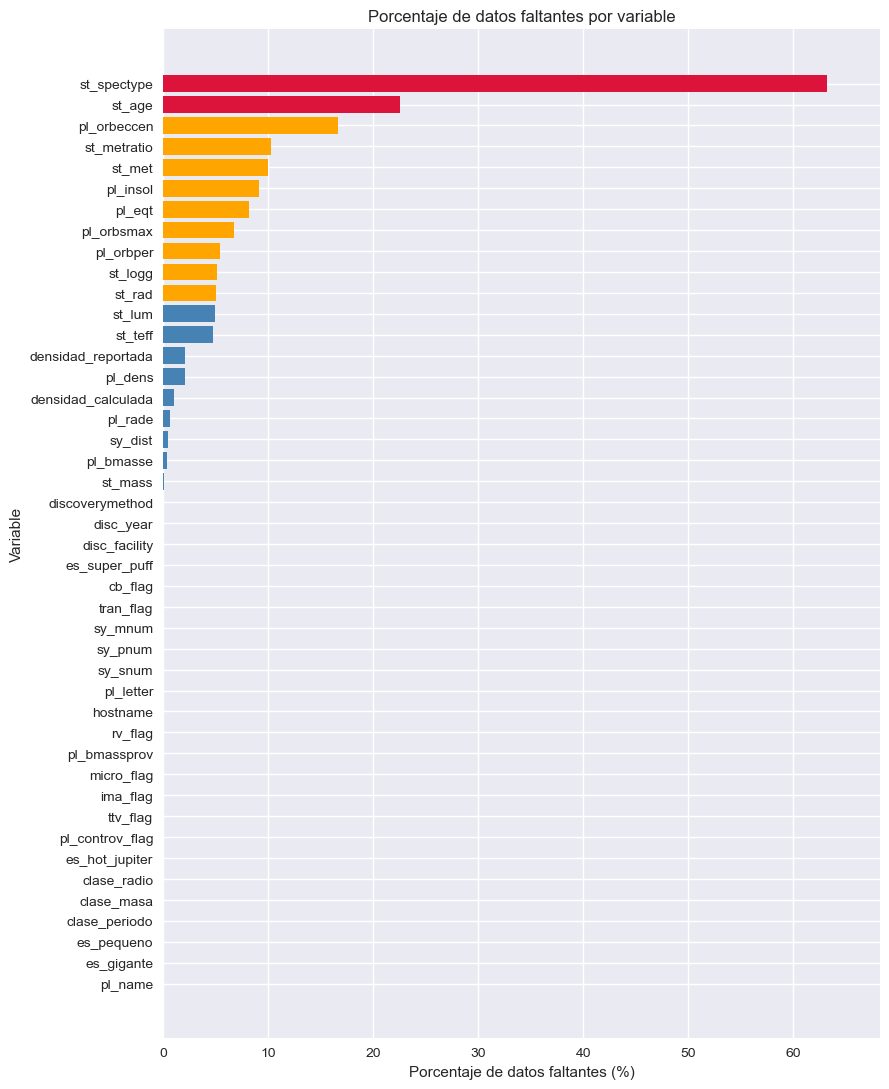

In [13]:
missing_fig = pd.DataFrame({
    "variable": df.columns,
    "porcentaje_faltante": df.isna().mean().values * 100
})

missing_fig = missing_fig.sort_values("porcentaje_faltante", ascending=True)

# Asignación de categorías por colores segúin porcentaje faltante 
colors = []
for value in missing_fig["porcentaje_faltante"]:
    if value == 0:
        colors.append("lightgray")
    elif value < 5:
        colors.append("steelblue")
    elif value < 20:
        colors.append("orange")
    else:
        colors.append("crimson")

plt.figure(figsize=(9, 11))
plt.barh(
    missing_fig["variable"],
    missing_fig["porcentaje_faltante"],
    color=colors
)

plt.xlabel("Porcentaje de datos faltantes (%)")
plt.ylabel("Variable")
plt.title("Porcentaje de datos faltantes por variable")

plt.xlim(0, max(missing_fig["porcentaje_faltante"]) + 5)

plt.tight_layout()
plt.savefig("../figures/fig_porcentaje_faltantes_variables.png", dpi=300)
plt.show()

In [5]:
conteo_metodo = df["discoverymethod"].value_counts().reset_index()
conteo_metodo.columns = ["metodo_descubrimiento", "numero_de_planetas"]

conteo_metodo["porcentaje"] = (
    100 * conteo_metodo["numero_de_planetas"] / conteo_metodo["numero_de_planetas"].sum()
).round(2)

conteo_metodo

,metodo_descubrimiento,numero_de_planetas,porcentaje
0,Transit,4660,74.36
1,Radial Velocity,1162,18.54
2,Microlensing,281,4.48
3,Imaging,95,1.52
4,Transit Timing Variations,40,0.64
5,Eclipse Timing Variations,8,0.13
6,Pulsar Timing,8,0.13
7,Astrometry,6,0.10
8,Orbital Brightness Modulation,4,0.06
9,Pulsation Timing Variations,2,0.03


In [6]:
conteo_metodo.to_csv("../tables/conteo_metodo_descubrimiento.csv", index=False)

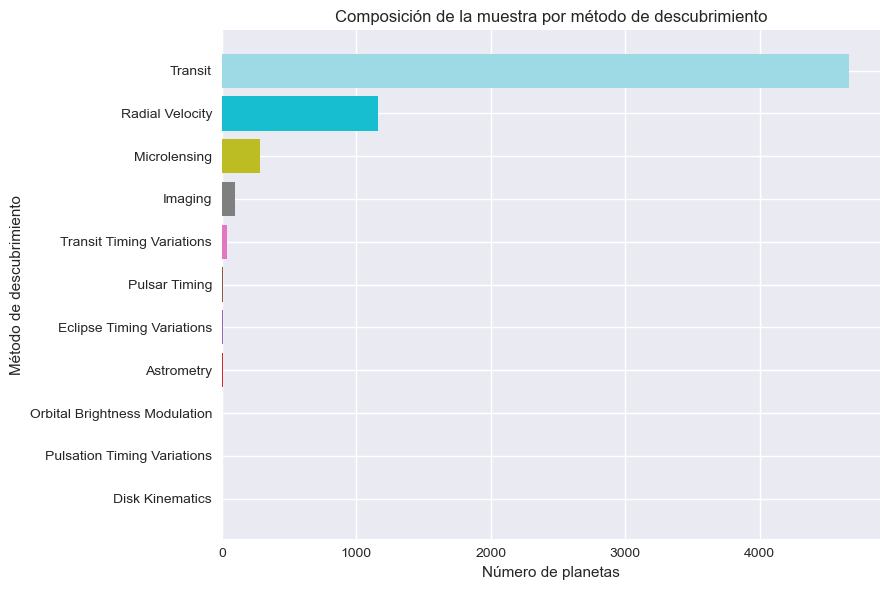

In [14]:
conteo_metodo_plot = conteo_metodo.sort_values("numero_de_planetas", ascending=True)

# Paleta de colores para que cada barra tenga un color distinto
colors = plt.cm.tab20(np.linspace(0, 1, len(conteo_metodo_plot)))

plt.figure(figsize=(9, 6))

plt.barh(
    conteo_metodo_plot["metodo_descubrimiento"],
    conteo_metodo_plot["numero_de_planetas"],
    color=colors
)

plt.xlabel("Número de planetas")
plt.ylabel("Método de descubrimiento")
plt.title("Composición de la muestra por método de descubrimiento")

plt.tight_layout()
plt.savefig("../figures/fig_composicion_metodo_descubrimiento.png", dpi=300)
plt.show()

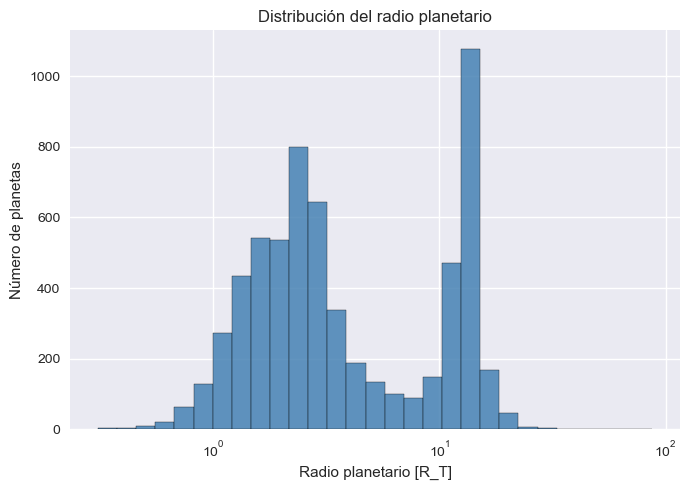

In [45]:
ddf_radio = df[df["pl_rade"].notna()].copy()

bins = np.logspace(
    np.log10(df["pl_rade"].min()),
    np.log10(df["pl_rade"].max()),
    30
)


plt.figure(figsize=(7, 5))
plt.hist(df_radio["pl_rade"], bins=bins, color="steelblue", edgecolor="black", alpha=0.85)



plt.xscale("log")
plt.xlabel("Radio planetario [R_T]")
plt.ylabel("Número de planetas")
plt.title("Distribución del radio planetario")
plt.tight_layout()
plt.savefig("../figures/fig_distribucion_radio_planetario_log.png", dpi=300)
plt.show()

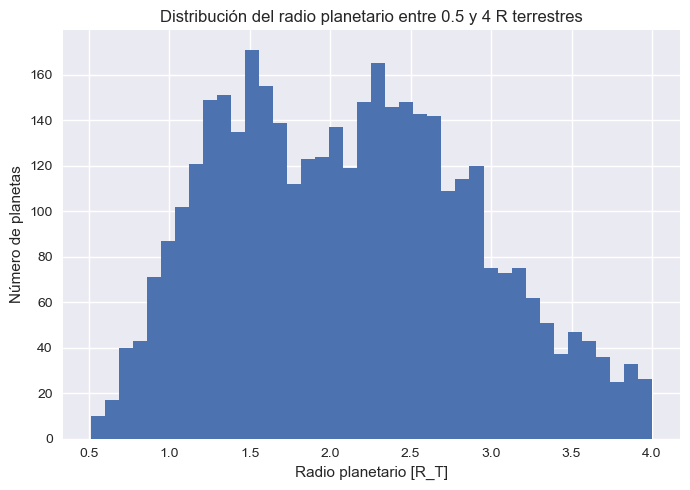

In [46]:
df_radius_gap = df[
    (df["pl_rade"].notna()) &
    (df["pl_rade"] >= 0.5) &
    (df["pl_rade"] <= 4.0)
].copy()

plt.figure(figsize=(7, 5))
plt.hist(df_radius_gap["pl_rade"], bins=40)
plt.xlabel("Radio planetario [R_T]")
plt.ylabel("Número de planetas")
plt.title("Distribución del radio planetario entre 0.5 y 4 R terrestres")
plt.tight_layout()
plt.savefig("../figures/fig_radius_gap_0p5_4_Rearth.png", dpi=300)
plt.show()

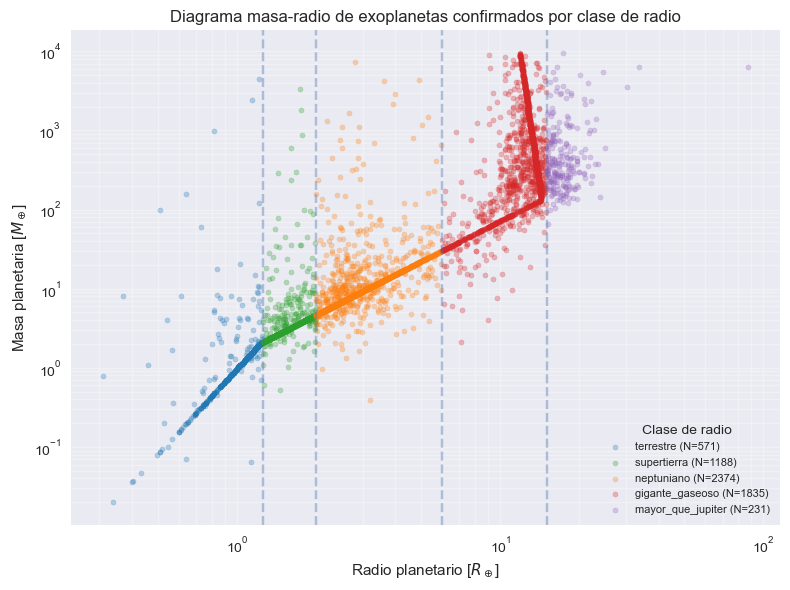

In [48]:
plt.figure(figsize=(8, 6))

for clase in clases_orden:
    subset = df_mr[df_mr["clase_radio"] == clase]

    plt.scatter(
        subset["pl_rade"],
        subset["pl_bmasse"],
        s=14,
        alpha=0.3,
        color=colores[clase],
        label=f"{clase} (N={len(subset)})"
    )

for limite in [1.25, 2, 6, 15]:
    plt.axvline(limite, linestyle="--", alpha=0.4)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Radio planetario [$R_\oplus$]")
plt.ylabel(r"Masa planetaria [$M_\oplus$]")
plt.title("Diagrama masa-radio de exoplanetas confirmados por clase de radio")

plt.legend(title="Clase de radio", fontsize=8)
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/fig_masa_radio_log_por_clase_radio.png", dpi=300)
plt.show()

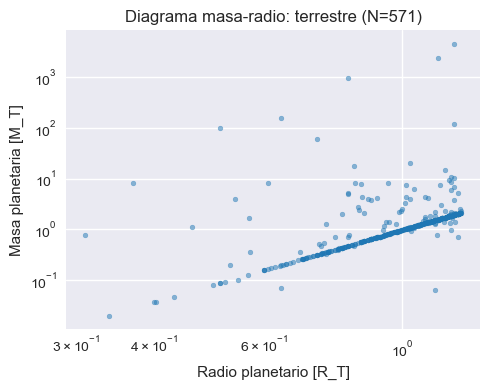

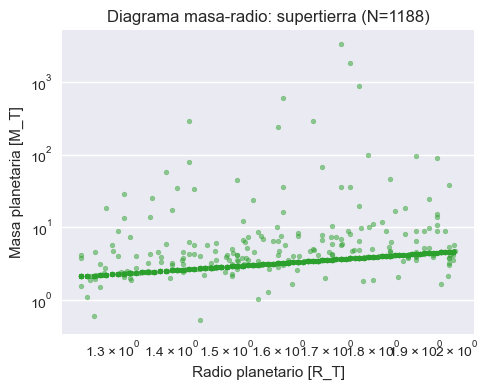

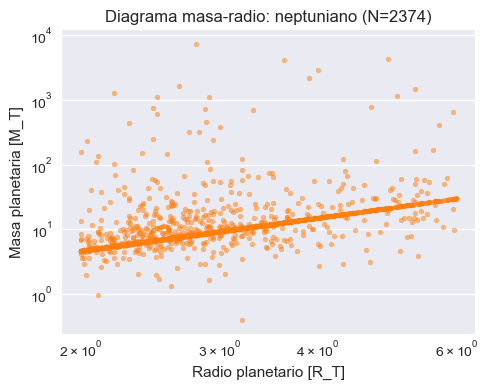

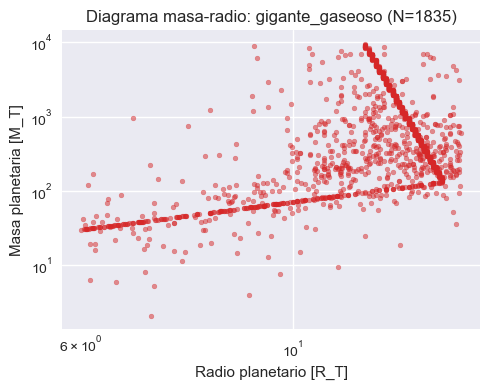

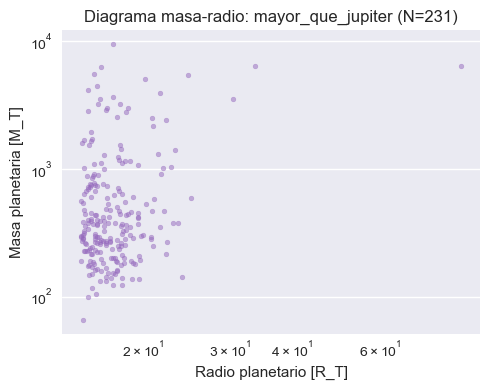

In [52]:
df_mr = df[
    df["pl_rade"].notna() &
    df["pl_bmasse"].notna() &
    (df["clase_radio"] != "sin_dato")
].copy()

clases = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

colores = {
    "terrestre": "tab:blue",
    "supertierra": "tab:green",
    "neptuniano": "tab:orange",
    "gigante_gaseoso": "tab:red",
    "mayor_que_jupiter": "tab:purple"
}

for clase in clases:
    subset = df_mr[df_mr["clase_radio"] == clase]

    plt.figure(figsize=(5, 4))
    plt.scatter(
        subset["pl_rade"],
        subset["pl_bmasse"],
        alpha=0.5,
        s=12,
        color=colores[clase]
    )

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Radio planetario [R_T]")
    plt.ylabel("Masa planetaria [M_T]")
    plt.title(f"Diagrama masa-radio: {clase} (N={len(subset)})")
    plt.tight_layout()
    plt.savefig(f"../figures/fig_masa_radio_{clase}.png", dpi=300)
    plt.show()

In [33]:
obs_radio = df["clase_radio"].value_counts(normalize=True).mul(100).round(2)
obs_periodo = df["clase_periodo"].value_counts(normalize=True).mul(100).round(2)
obs_metodo = df["discoverymethod"].value_counts(normalize=True).mul(100).round(2)

display(obs_radio)
display(obs_periodo)
display(obs_metodo)

clase_radio
neptuniano           37.88
gigante_gaseoso      29.57
supertierra          18.96
terrestre             9.11
mayor_que_jupiter     3.78
sin_dato              0.70
Name: proportion, dtype: float64

clase_periodo
periodo_corto         43.00
periodo_intermedio    33.51
periodo_largo         15.53
sin_dato               5.43
USP                    2.54
Name: proportion, dtype: float64

discoverymethod
Transit                          74.36
Radial Velocity                  18.54
Microlensing                      4.48
Imaging                           1.52
Transit Timing Variations         0.64
Eclipse Timing Variations         0.13
Pulsar Timing                     0.13
Astrometry                        0.10
Orbital Brightness Modulation     0.06
Pulsation Timing Variations       0.03
Disk Kinematics                   0.02
Name: proportion, dtype: float64

After accounting for the flexible mass–radius relation and incident flux, stellar mass remains positively associated with planetary mass residuals. A one-standard-deviation increase in stellar mass corresponds to an increase of 0.075 dex in ΔlogMp, with IC95% [0.030, 0.119]. The metallicity coefficient is positive but its confidence interval crosses zero, so it is not robust in this model.